## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [635]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

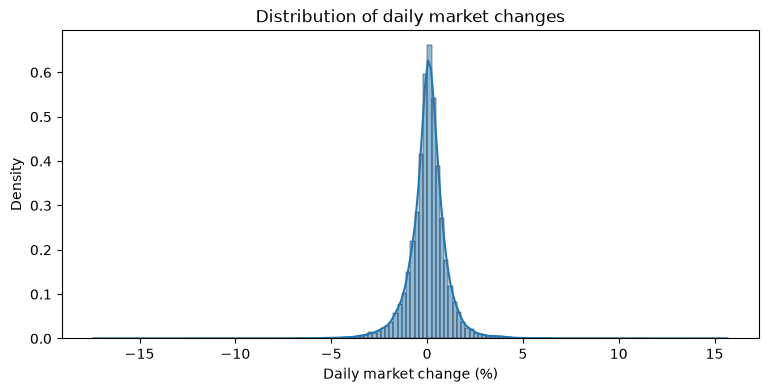

In [636]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

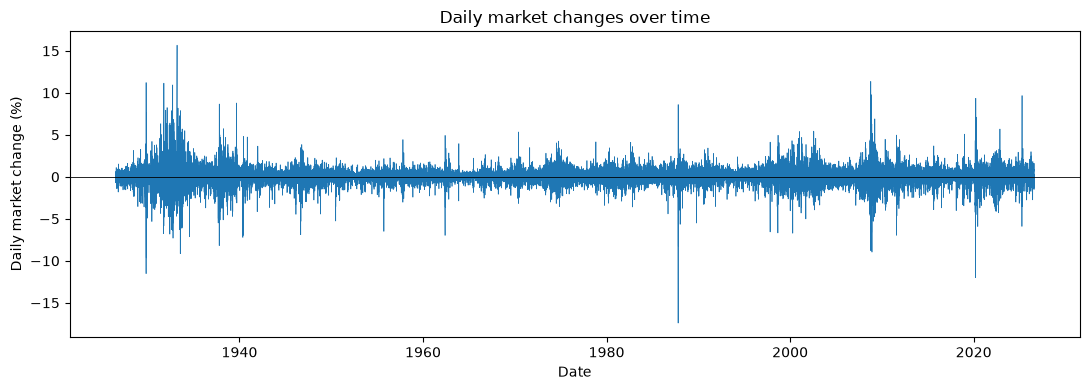

In [637]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [638]:
# make a categorical column "direction_t" 
direction_catefories = ["Down / Flat", "Up"]
np.where(df["market_return_pct"] > 0, "Up", "Down/Flat")
df['direction_t'] = pd.Categorical(np.where(df["market_return_pct"] > 0, "Up", "Down/Flat"))

In [639]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df["direction_t"].shift(-1)

In [640]:
df[["direction_t", "direction_tp1"]]

,direction_t,direction_tp1
0,Up,Up
1,Up,Up
2,Up,Up
3,Up,Up
4,Up,Down/Flat
...,...,...
26291,Up,Up
26292,Up,Down/Flat
26293,Down/Flat,Up
26294,Up,Up


In [641]:
pd.crosstab(df["direction_t"], df["direction_tp1"])

direction_tp1,Down/Flat,Up
direction_t,,
Down/Flat,5909,5999
Up,5999,8388


In [642]:
pd.crosstab(df["direction_t"], df["direction_tp1"], normalize=True, margins = True)

direction_tp1,Down/Flat,Up,All
direction_t,,,
Down/Flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


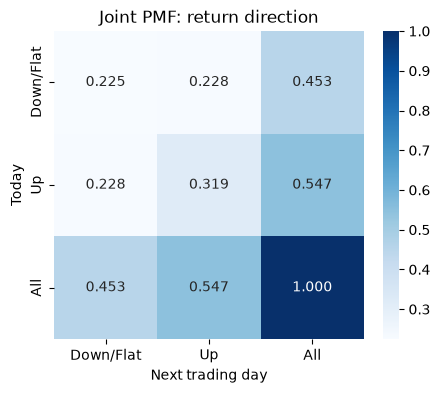

In [643]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["direction_t"], df["direction_tp1"], normalize=True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [644]:
# Plot the conditional PMF
pd.crosstab(df["direction_t"], df["direction_tp1"], normalize="index", margins=True)

direction_tp1,Down/Flat,Up
direction_t,,
Down/Flat,0.496221,0.503779
Up,0.416974,0.583026
All,0.452862,0.547138


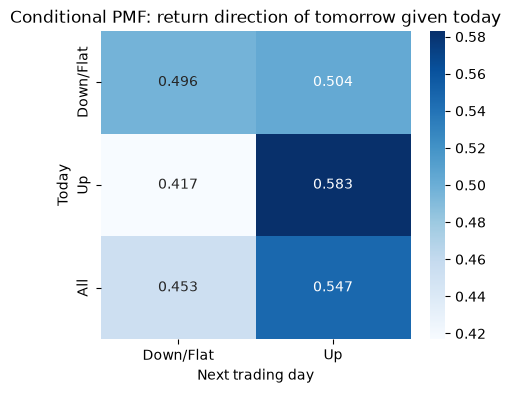

In [645]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["direction_t"], df["direction_tp1"], normalize="index", margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: return direction of tomorrow given today')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

An up transition, defined as tomorrow being up, is more common than down transitions (tomorrow being down). This can be seen from assessing the marginals of up and down for tomorrow. The marginal probability of tomorrow being up is 0.547 compared to the probability of tomorrow being down, which is 0.453. The second part of the question requires us to compare the conditional probability of up tomorrow given down today and up tomorrow given up today. The probability of up tomorrow given down today is 0.504, whereas the probability of up tomorrow given up today is 0.583. Thus, we are more likely to transition to an up day from an up day. 

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [646]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df["market_return_pct"], bins = [-np.inf, -1, -.1, .1, 1, np.inf], labels = return_categories)

In [647]:
df['return_bin']

0         Near zero
1        Small gain
2        Small gain
3         Near zero
4        Small gain
            ...    
26291    Small gain
26292    Small gain
26293    Large loss
26294    Large gain
26295    Small gain
Name: return_bin, Length: 26296, dtype: category
Categories (5, object): ['Large loss' < 'Small loss' < 'Near zero' < 'Small gain' < 'Large gain']

In [648]:
df['return_bin'].value_counts()

return_bin
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

In [649]:
#make y_t and y_tp1 columns for the return bins
df["y_t"] = df["return_bin"]
df["y_tp1"] = df["return_bin"].shift(-1)

<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

9,785 days fall into small gain, 7,452 days fall into small loss, 3,441 days fall into near zero, 2,859 fall into large gain, and 2,759 fall into large loss. The most common is small gain (9,785 days) and the least common is large loss (2,759 days).

In [650]:
#joint PMF with marginals
pd.crosstab(df["y_t"], df["y_tp1"], normalize=True, margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


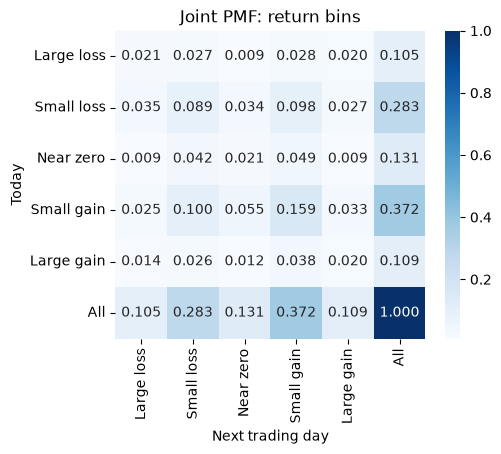

In [651]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["y_t"], df["y_tp1"], normalize=True, margins = True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

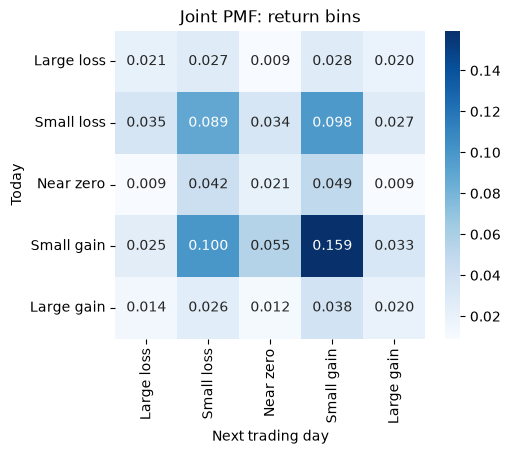

In [652]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["y_t"], df["y_tp1"], normalize=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

Generally, the transitions that are most likely to occur are small-small transitions. The four largest joint probabilities are small gain-small gain (0.159), small gain-small loss (0.1), small loss-small gain (0.098), and small loss-small loss (0.089).

In [653]:
#conditional PMF 
pd.crosstab(df["y_t"], df["y_tp1"], normalize="index", margins=True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281
All,0.104925,0.283400,0.130823,0.372124,0.108728


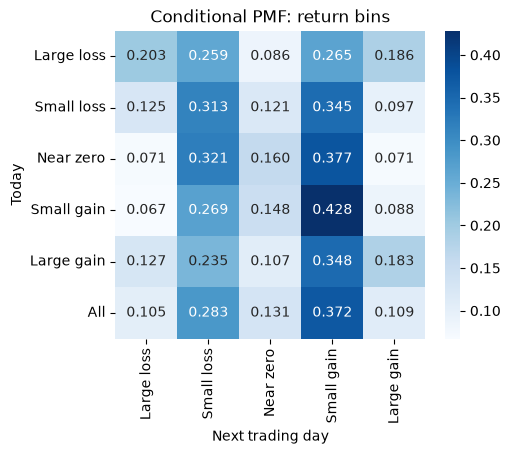

In [654]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(pd.crosstab(df["y_t"], df["y_tp1"], normalize="index", margins=True),
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Conditional PMF: return bins')
plt.show()

In [655]:
tom_marginal = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)
today_marginal = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=1)

In [656]:
tom_marginal

y_tp1
Large loss    0.104925
Small loss    0.283400
Near zero     0.130823
Small gain    0.372124
Large gain    0.108728
dtype: float64

In [657]:
today_marginal

y_t
Large loss    0.104925
Small loss    0.283400
Near zero     0.130861
Small gain    0.372086
Large gain    0.108728
dtype: float64

In [658]:
independence = pd.DataFrame(np.outer(today_marginal, tom_marginal), index=today_marginal.index, columns=tom_marginal.index)

In [659]:
indpendence_diff = independence - pd.crosstab(df["y_t"], df["y_tp1"], normalize=True)

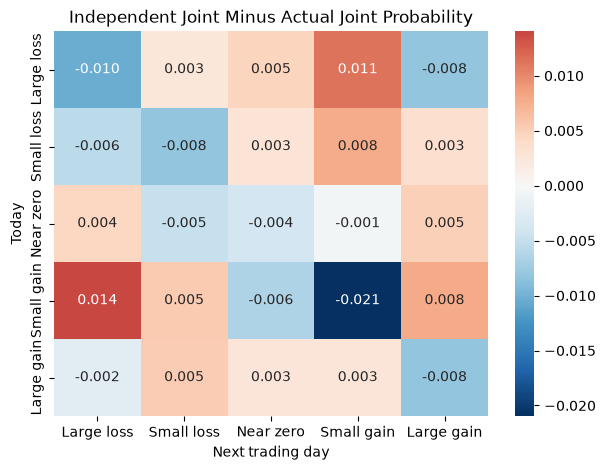

In [660]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(indpendence_diff,
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Independent Joint Minus Actual Joint Probability')
plt.show()

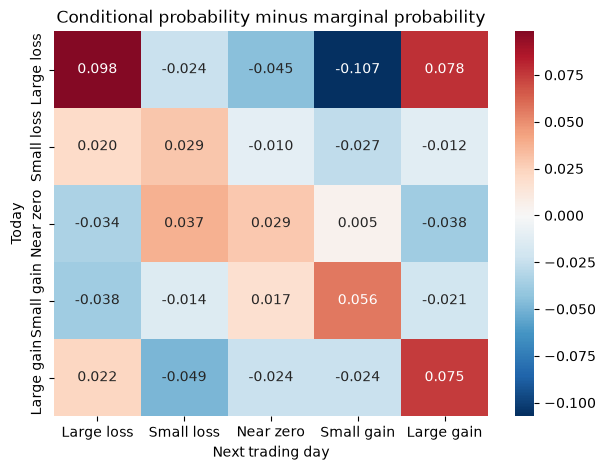

In [661]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True).sum(axis=0)

conditional = pd.crosstab(df['y_t'], df['y_tp1'], normalize="index")
# subtract it from each row of the conditional PMF and plot as a heatmap
# hint: use .sub(next_state_pmf, axis='columns'), and a diverging colormap such as cmap='RdBu_r' with center=0
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(conditional.sub(next_state_pmf, axis='columns'),
            annot=True, fmt='.3f', center=0, cmap='RdBu_r', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional probability minus marginal probability')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

From the independence and joint comparison, we see a pattern of negative values along the diagonal. That is, indpendence would predict a lower probability of these pairs than the actual joint does. Since our columns are organized ordinally, this means that matching (or close) outcomes today and tomorrow are slightly more likely than independence would suggest, meaning they are associated. Interestingly, for a large gain today and a large loss tomorrow (or vice versa), independence also predicts less co-occurrence than reality, meaning they are associated; this pattern will repeat later. In general, events that are less likely than indepedence predicts are mostly small-large or large-small outcomes, suggesting that these outcomes don't tend to go together as much; this pattern will repeat later.

While information about today varies our outlook on tomorrow, it doesn't do so in a dramatic way; the marginal distribution for tomorrow's transition only varies slightly from the conditional distributions, which is symbolized through most of the heat map entries of the marginal conditional difference above being close to 0. That is, while they may vary numerically, they mostly preserve the same "shape" or trends. 

The comparison in the first bullet is comparing the true distribution to a hypothetical joint distribution in which the two outcomes are independent, resulting in a joint pmf that is just the product of the marginals. The comparison in the second bullet is comparing each conditional distribution of next trading day outcome given a current trading day outcome (5 such distributions) to the unconditional distribution of next trading day outcome. When we compare each row to a uniform PMF with probability .2, we are really comparing each conditional distribution (5 such distributions) to a hypotheized conditional distribution in which all tomorrow outcomes are equally likely given today's outcome. 

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

For each current state, the two future states that are most likely is small loss and small gain, with small gain being generally more likely; this is visually symbolized by the vertical stripes in the second and fourth columns. If each row were a uniform mass function, then each column entry would be 0.2, meaning the conditional probability of any tomorrow outcome given any today outcome would be 0.2. Subjectively, most rows would not be well approximated by a uniform mass function. Indeed, small loss and large gain have conditional probabilities that far exceed 0.2 (in some cases roughly double!), whereas large loss, near zero, and large gain generally fall far below 0.2 (in some cases roughly half or a quarter!). 

I would say it is relatively difficult to predict the next state. While information about today varies our outlook on tomorrow, it doesn't do so in a dramatic way; the marginal distribution for tomorrow's transition only varies slightly from the conditional distributions, which is symbolized through most of the heat map entries above being close to 0. Moreover, conditioned or unconditioned, no group is resoundly dominant; while it is true that small gains and small losses are more probable than their counterparts, neither of them ever occur with a (conditional or unconditional) probability that exceeds $0.43$. Still, I would be somewhat confident that the next state is small; unconditionally, such small tomorrow outcomes occur almost two thirds of the time. This makes sense from the KDE, where we saw a lot of density around (but not quite) 0.

In [662]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
# use groupby and describe/mean to get the conditional expectation of the next day's return given today's return bin y_t

df.groupby("y_t")["market_return_pct_tp1"].describe()

/var/folders/wn/4vhmdq557_7f8325xdqxk2tr0000gn/T/ipykernel_89248/307657346.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby("y_t")["market_return_pct_tp1"].describe()


,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


Given a large loss in the current state, we would expect a mean return of $-0.038\%$. Given a small loss in the current state, we would expect a mean return of $-0.044\%$. Given a near zero change in the current state, we would expect a mean return of $0.015\%$. Given a small gain in the current state, we would expect a mean return of $0.11\%$. Finally, given a large gain in the current state, we would expect a mean return of $0.163\%$. In general, min and max values grow large in magnitude as the extremeness of the observed day grows. That is, if today was a large gain or a large loss, we expect maximum values and minimum values further from 0. Alternatively, for small loss, near zero, and small gain, the range of values is much smaller. That, is if today saw a small change, we expect maximum and minimum values closer to 0 (a much smaller range). The same trend is repeated with standard deviations, where large loss and large gain have the largest standard deviations, and small loss, near zero, and small gain have much smaller standard deviations. The analysis of min and max values and standard deviations convey the same general message; extreme todays make for volatile tomorrows, and this volatility is relatively (but not exactly) symmetric, meaning an large gain today can plausibly be followed by an large loss tomorrow (and vice versa). 

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [663]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [664]:
#joint PMF with marginals for the 21 quantile bins + plot as heatmap
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = True
)

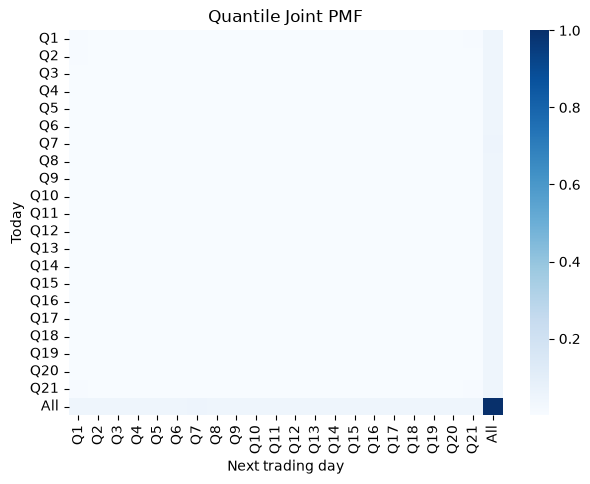

In [665]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(quantile_joint,
            fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Quantile Joint PMF')
plt.show()

In [675]:
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)

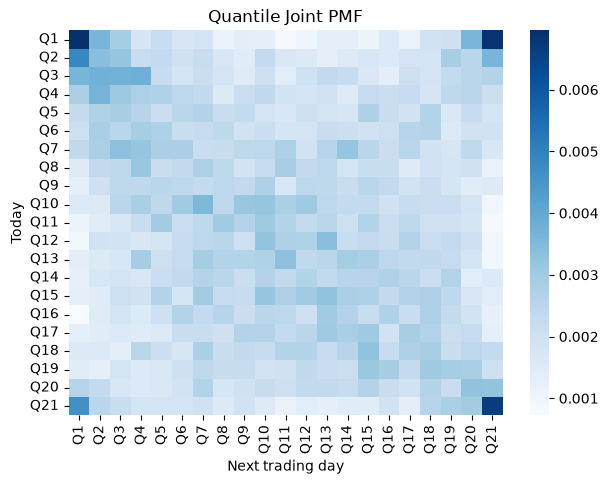

In [677]:
fig, ax = plt.subplots(figsize=(7, 5))

sns.heatmap(quantile_joint,
            fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Quantile Joint PMF')
plt.show()

<Axes: xlabel='y_tp1', ylabel='y_t'>

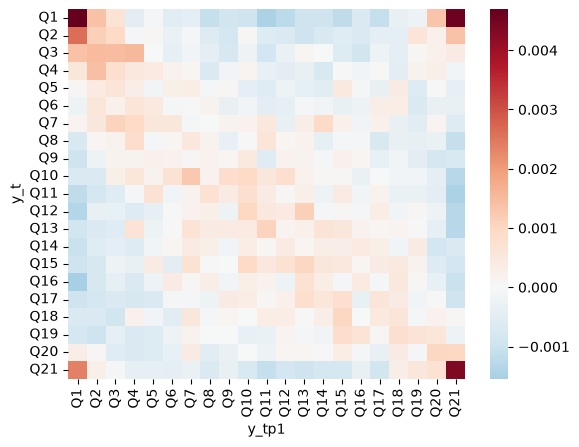

In [668]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

There are two obvious patterns. Visually, we see a well-defined red diagonal spanning from top left to bottom right and a lesser but still defined diagonal between the other two corners. The first well-defined red diagonal roughly corresponds to joint outcomes where the return on today and tomorrow are relatively similar. The red in this region indicates that our joint pmf expects these co-ocurrences to occur more than if two-day outcomes were independent and marginally uniform; the strength of the red is most apparent in the corners, suggesting that similar outcomes in repeated days is especially true for more extreme outcomes. The opposite diagonal represents when the return between today and tomorrow are of equal extreme but in the opposite direction. This is really only defined strongly in the corners; this suggests that large gain today and large loss tomorrow (or vice versa) occur more than if the two-day outcomes were independent and marginally uniform.  

<Axes: xlabel='y_tp1', ylabel='y_t'>

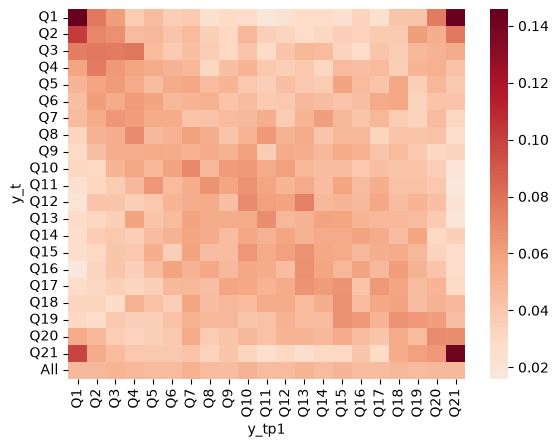

In [669]:
quantile_conditional = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize="index", margins = True
)

# compute and plot the conditional
sns.heatmap(quantile_conditional, cmap='RdBu_r', center=0)

<Axes: xlabel='y_tp1', ylabel='y_t'>

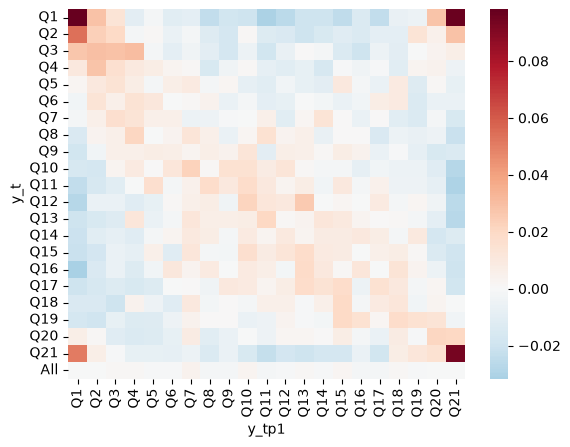

In [670]:
# Subtract 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, 
# and see systematic deviations from uniformly random behavior.
sns.heatmap(quantile_conditional - 1/bins, cmap='RdBu_r', center=0)

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

In general, the conditional pmfs more or less convey the same message as before. For the sake of being brief, the red positive diagonal suggests that days tend to repeat; given a certain outcome happened today, the probability of a similar outcome tomorrow is relatively high. Again, the corners of the negative diagonal are also quite red; this suggests that if a large gain (loss) today occurred, the probability of a large loss (gain) tomorrow is relatively high. This agrees with the earlier interpretation that volatility is positively related with the magnitude of today's return. 

In [680]:
# compute the next day's min, mean, and max conditional on each bin
stats = df.groupby("y_t")['market_return_pct_tp1'].describe()

/var/folders/wn/4vhmdq557_7f8325xdqxk2tr0000gn/T/ipykernel_89248/4109296162.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = df.groupby("y_t")['market_return_pct_tp1'].describe()


In [683]:
stats

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Q1,1255.0,-0.013713,2.140465,-17.41,-0.9150,-0.02,0.9000,11.22
Q2,1253.0,-0.076712,1.285882,-7.36,-0.7400,-0.02,0.6000,6.36
Q3,1286.0,-0.097084,1.227976,-8.79,-0.7100,-0.03,0.4700,11.36
Q4,1280.0,-0.058594,1.049607,-8.28,-0.5800,0.00,0.4925,6.16
Q5,1230.0,-0.024211,0.989470,-6.89,-0.4675,0.02,0.4675,4.56
Q6,1226.0,-0.022692,1.024761,-11.23,-0.4975,0.02,0.5000,6.37
Q7,1371.0,-0.030241,0.930389,-3.94,-0.4950,0.03,0.4100,7.37
Q8,1206.0,-0.014303,0.835663,-3.40,-0.4200,0.03,0.4100,4.76
Q9,1198.0,0.025860,0.853220,-6.00,-0.3900,0.03,0.4400,5.49


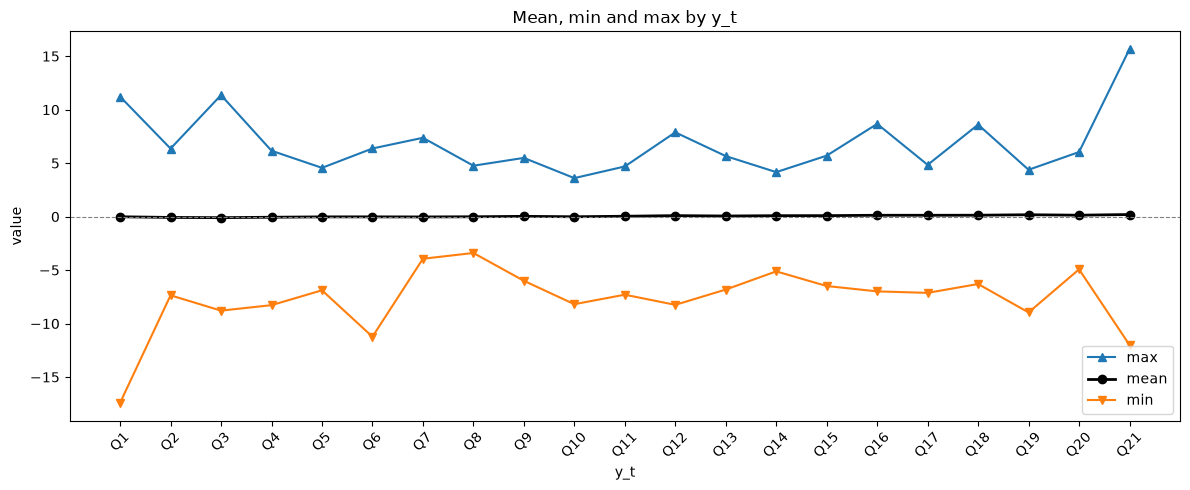

In [682]:
#plot as lines on a graph against the bins
x = stats.index.astype(str)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x, stats['max'], marker='^', label='max')
ax.plot(x, stats['mean'], marker='o', color='black', linewidth=2, label='mean')
ax.plot(x, stats['min'], marker='v', label='min')

ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel('y_t')
ax.set_ylabel('value')
ax.set_title('Mean, min and max by y_t')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

What is most striking about this visual is two things. First, the mean remains relatively stable, and this makes sense. Conceptually, our prior visuals showed that given a certain outcome happened today, the probability of a similar outcome tomorrow is relatively high but the probability of an opposite yet equally extreme outcome is also relatively high (especially true for extreme quantiles and weakly true elsewhere). The point is that if these probabilities of occurence are relatively similar, we have a "cancelling" effect in the expectation; loosely, when we go to integrate for the conditional expectation, we will always be adding up to terms of equal magnitude but in opposite signage. Note that this isn't exactly true; there tends to be slight asymmetry towards the signage of the previous day, meaning our means are usually slightly above or below 0, in the direction of the previous day. Another important observation is the shape of the minimum and maximum lines. Roughly, they bow out, signifying that extrema are smaller for intermediate quartiles and larger for extreme quartiles. Again, this aligns with the previous discussion of volatility. 

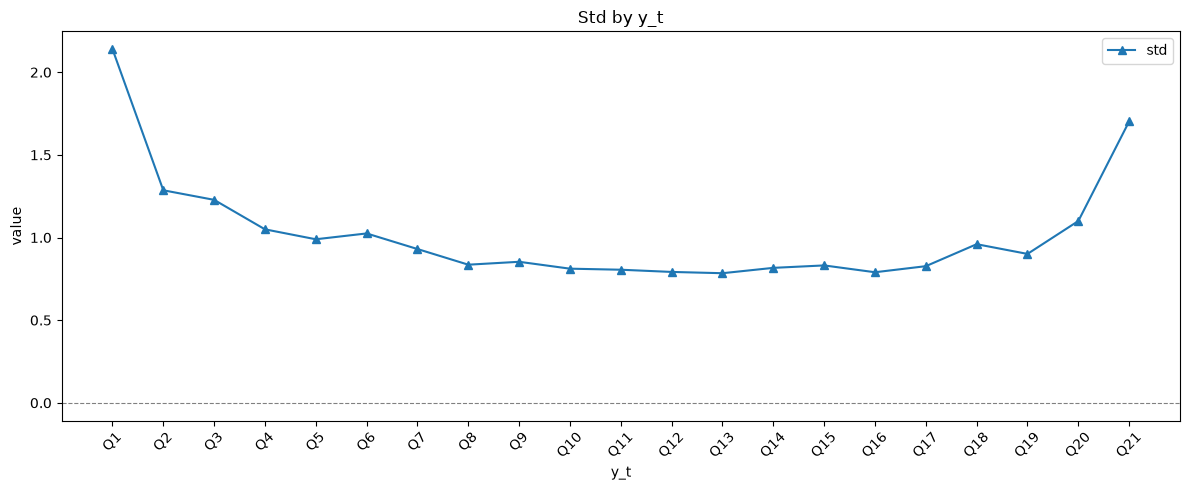

In [685]:
#compute the next day's standard deviation, and plot it as a line graph against the bins. 
x = stats.index.astype(str)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x, stats['std'], marker='^', label='std')

ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_xlabel('y_t')
ax.set_ylabel('value')
ax.set_title('Std by y_t')
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

As echoed before, the standard deviation produces a parabolic shape centered around 0 the middle quartile, meaning that as quartiles become increasingly extreme, standard deviation correspondingly increases at an increasing rate. This agrees with the earlier interpretation that volatility is positively related with the magnitude of today's return since the middle quartiles are about $0$. This also makes sense with our previous zero mean discussion. Most intermediate quantiles have most of their returns near zero, resulting in a distribution of clustered values around 0 with mean 0. More extreme quantiles have most of their outcomes distributed at extreme quantiles in both directions. So, while their center is also roughly 0, their distribution appears sort of bimodal, and the points in each cluster are quite a far distance from the mean of zero. 

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

The market is obviously difficult to predict, though I will note that my understanding of the market was made increasingly precise by changing the granularity of the conditioning information. With 5 bins, it is very easy to convince yourself that the conditional distributions for these bins are relatively homogenous, meaning that knowing the bin of the previous today is not very helpful in predicting the bin of the next; similarly, the volatility trend is obscured more. However, when we condition on more detailed information (namely, 21 equally populated bins), the picture becomes much clearer. Indeed, intermediate quantile days tend to precede intermediate quantile days (meaning less volatility), whereas extreme quantile days tend to precede extreme quantile days (meaning more volatility). Thus, attempting to predict market behavior after extreme days is more challenging. 